In [2]:
import os, re, gc, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 200)
pd.set_option('display.max_rows', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_style('whitegrid')

RANDOM_STATE = 42
IMG_DIR = 'images'
os.makedirs(IMG_DIR, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(f'{IMG_DIR}/{name}.png', dpi=150, bbox_inches='tight')

In [3]:
DATA_DIR = '.'   # CSV satu folder dengan notebook; ubah kalau ada di folder lain

REQUIRED = ['application_train', 'application_test', 'bureau', 'bureau_balance', 'POS_CASH_balance',
            'credit_card_balance', 'previous_application', 'installments_payments',
            'HomeCredit_columns_description']
missing_files = [f for f in REQUIRED if not os.path.exists(f'{DATA_DIR}/{f}.csv')]
if missing_files:
    raise FileNotFoundError(f'File berikut belum ada di "{DATA_DIR}": {missing_files}. Cek DATA_DIR / nama file.')
print('Semua file ditemukan:', [f for f in sorted(os.listdir(DATA_DIR)) if f.endswith('.csv')])

Semua file ditemukan: ['HomeCredit_columns_description.csv', 'POS_CASH_balance.csv', 'application_test.csv', 'application_test_merged.csv', 'application_train.csv', 'application_train_merged.csv', 'bureau.csv', 'bureau_balance.csv', 'credit_card_balance.csv', 'installments_payments.csv', 'previous_application.csv', 'sample_submission.csv', 'submission.csv']


In [4]:
desc = pd.read_csv(f'{DATA_DIR}/HomeCredit_columns_description.csv', encoding='latin-1', index_col=0)
print(desc.groupby('Table').size())

pd.set_option('display.max_colwidth', 160)
display(desc[desc['Table'].str.contains('application_')][['Row', 'Description', 'Special']].reset_index(drop=True))
pd.set_option('display.max_colwidth', 50)

Table
POS_CASH_balance.csv              8
application_{train|test}.csv    122
bureau.csv                       17
bureau_balance.csv                3
credit_card_balance.csv          23
installments_payments.csv         8
previous_application.csv         38
dtype: int64


,Row,Description,Special
0,SK_ID_CURR,ID of loan in our sample,NaN
1,TARGET,Target variable (1 - client with payment difficulties: he/she had late payment more than X days on at least one of the first Y installments of the loan in o...,NaN
2,NAME_CONTRACT_TYPE,Identification if loan is cash or revolving,NaN
3,CODE_GENDER,Gender of the client,NaN
4,FLAG_OWN_CAR,Flag if the client owns a car,NaN
5,FLAG_OWN_REALTY,Flag if client owns a house or flat,NaN
6,CNT_CHILDREN,Number of children the client has,NaN
7,AMT_INCOME_TOTAL,Income of the client,NaN
8,AMT_CREDIT,Credit amount of the loan,NaN
9,AMT_ANNUITY,Loan annuity,NaN


In [5]:
tables = ['application_train', 'application_test', 'bureau', 'bureau_balance', 'POS_CASH_balance',
          'credit_card_balance', 'previous_application', 'installments_payments']
summary = []
for name in tables:
    df_ = pd.read_csv(f'{DATA_DIR}/{name}.csv')
    summary.append({
        'table': name, 'rows': len(df_), 'cols': df_.shape[1],
        'memory_MB': df_.memory_usage(deep=True).sum() / 1e6,
        'dup_rows': int(df_.duplicated().sum()) if len(df_) < 4_000_000 else np.nan,
        'cols_with_missing': int(df_.isna().any().sum()),
        'max_missing_%': df_.isna().mean().max() * 100,
    })
    del df_; gc.collect()
display(pd.DataFrame(summary))

,table,rows,cols,memory_MB,dup_rows,cols_with_missing,max_missing_%
0,application_train,307511,122,529.5155,0.0000,67,69.8723
1,application_test,48744,121,83.5642,0.0000,64,68.7161
2,bureau,1716428,17,495.7928,0.0000,7,71.4735
3,bureau_balance,27299925,3,"1,801.7952",NaN,0,0.0000
4,POS_CASH_balance,10001358,8,"1,112.4824",NaN,2,0.2608
5,credit_card_balance,3840312,23,887.5026,0.0000,9,19.9981
6,previous_application,1670214,37,"1,785.7354",0.0000,16,99.6437
7,installments_payments,13605401,8,870.7458,NaN,2,0.0214


In [6]:
app_train = pd.read_csv(f'{DATA_DIR}/application_train.csv')
app_test = pd.read_csv(f'{DATA_DIR}/application_test.csv')
print('train:', app_train.shape, '| test:', app_test.shape)
display(app_train.head())
print(app_train.dtypes.value_counts())

train: (307511, 122) | test: (48744, 121)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,COMMONAREA_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,FLOORSMIN_MODE,LANDAREA_MODE,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,"202,500.0000","406,597.5000","24,700.5000","351,000.0000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0188,-9461,-637,"-3,648.0000",-2120,NaN,1,1,0,1,1,0,Laborers,1.0000,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.0830,0.2629,0.1394,0.0247,0.0369,0.9722,0.6192,0.0143,0.0000,0.0690,0.0833,0.1250,0.0369,0.0202,0.0190,0.0000,0.0000,0.0252,0.0383,0.9722,0.6341,0.0144,0.0000,0.0690,0.0833,0.1250,0.0377,0.0220,0.0198,0.0000,0.0000,0.0250,0.0369,0.9722,0.6243,0.0144,0.0000,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.0000,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0000,2.0000,2.0000,2.0000,"-1,134.0000",0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000
1,100003,0,Cash loans,F,N,N,0,"270,000.0000","1,293,502.5000","35,698.5000","1,129,500.0000",Family,State servant,Higher education,Married,House / apartment,0.0035,-16765,-1188,"-1,186.0000",-291,NaN,1,1,0,1,1,0,Core staff,2.0000,1,1,MONDAY,11,0,0,0,0,0,0,School,0.3113,0.6222,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.0800,0.0345,0.2917,0.3333,0.0130,0.0773,0.0549,0.0039,0.0098,0.0924,0.0538,0.9851,0.8040,0.0497,0.0806,0.0345,0.2917,0.3333,0.0128,0.0790,0.0554,0.0000,0.0000,0.0968,0.0529,0.9851,0.7987,0.0608,0.0800,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.0100,reg oper account,block of flats,0.0714,Block,No,1.0000,0.0000,1.0000,0.0000,-828.0000,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
2,100004,0,Revolving loans,M,Y,Y,0,"67,500.0000","135,000.0000","6,750.0000","135,000.0000",Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.0100,-19046,-225,"-4,260.0000",-2531,26.0000,1,1,1,1,1,0,Laborers,1.0000

float64    65
int64      41
str        16
Name: count, dtype: int64


In [7]:
# Distribusi target
base_rate = app_train['TARGET'].mean()
print(app_train['TARGET'].value_counts())
print(f'Default rate: {base_rate:.2%} | imbalance ratio (0:1) = {(1-base_rate)/base_rate:.1f} : 1')

# Missing values
miss = app_train.isna().mean().sort_values(ascending=False)
display((miss.head(25) * 100).to_frame('missing_%'))
print('Jumlah kolom missing >50%:', int((miss > 0.5).sum()), '| >30%:', int((miss > 0.3).sum()))

# Kardinalitas kategorikal
cat_cols_raw = app_train.select_dtypes('object').columns
display(app_train[cat_cols_raw].nunique().to_frame('n_unique'))

TARGET
0    282686
1     24825
Name: count, dtype: int64
Default rate: 8.07% | imbalance ratio (0:1) = 11.4 : 1


,missing_%
COMMONAREA_AVG,69.8723
COMMONAREA_MODE,69.8723
COMMONAREA_MEDI,69.8723
NONLIVINGAPARTMENTS_MEDI,69.4330
NONLIVINGAPARTMENTS_MODE,69.4330
NONLIVINGAPARTMENTS_AVG,69.4330
FONDKAPREMONT_MODE,68.3862
LIVINGAPARTMENTS_AVG,68.3550
LIVINGAPARTMENTS_MEDI,68.3550
LIVINGAPARTMENTS_MODE,68.3550


Jumlah kolom missing >50%: 41 | >30%: 50


,n_unique
NAME_CONTRACT_TYPE,2
CODE_GENDER,3
FLAG_OWN_CAR,2
FLAG_OWN_REALTY,2
NAME_TYPE_SUITE,7
NAME_INCOME_TYPE,8
NAME_EDUCATION_TYPE,5
NAME_FAMILY_STATUS,6
NAME_HOUSING_TYPE,6
OCCUPATION_TYPE,18


In [8]:
# Cek anomali / kualitas data
print('DAYS_EMPLOYED == 365243 :', int((app_train['DAYS_EMPLOYED'] == 365243).sum()),
      f"({(app_train['DAYS_EMPLOYED'] == 365243).mean():.1%})")
for c in ['CODE_GENDER', 'ORGANIZATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_INCOME_TYPE']:
    print(c, '-> XNA/Unknown:', int(app_train[c].isin(['XNA', 'Unknown']).sum()))
print('Umur (tahun) min/max:', (-app_train['DAYS_BIRTH'] / 365).min().round(1), (-app_train['DAYS_BIRTH'] / 365).max().round(1))

display(app_train[['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'CNT_CHILDREN', 'DAYS_EMPLOYED',
                   'OBS_30_CNT_SOCIAL_CIRCLE', 'AMT_REQ_CREDIT_BUREAU_QRT']]
        .describe(percentiles=[.01, .5, .99, .999]).T)

DAYS_EMPLOYED == 365243 : 55374 (18.0%)
CODE_GENDER -> XNA/Unknown: 4
ORGANIZATION_TYPE -> XNA/Unknown: 55374
NAME_FAMILY_STATUS -> XNA/Unknown: 2
NAME_INCOME_TYPE -> XNA/Unknown: 0
Umur (tahun) min/max: 20.5 69.1


,count,mean,std,min,1%,50%,99%,99.9%,max
AMT_INCOME_TOTAL,"307,511.0000","168,797.9193","237,123.1463","25,650.0000","45,000.0000","147,150.0000","472,500.0000","900,000.0000","117,000,000.0000"
AMT_CREDIT,"307,511.0000","599,025.9997","402,490.7770","45,000.0000","76,410.0000","513,531.0000","1,854,000.0000","2,517,300.0000","4,050,000.0000"
AMT_ANNUITY,"307,499.0000","27,108.5739","14,493.7373","1,615.5000","6,182.9100","24,903.0000","70,006.5000","110,047.5000","258,025.5000"
CNT_CHILDREN,"307,511.0000",0.4171,0.7221,0.0000,0.0000,0.0000,3.0000,4.0000,19.0000
DAYS_EMPLOYED,"307,511.0000","63,815.0459","141,275.7665","-17,912.0000","-10,894.9000","-1,213.0000","365,243.0000","365,243.0000","365,243.0000"
OBS_30_CNT_SOCIAL_CIRCLE,"306,490.0000",1.4222,2.4010,0.0000,0.0000,0.0000,10.0000,17.0000,348.0000
AMT_REQ_CREDIT_BUREAU_QRT,"265,992.0000",0.2655,0.7941,0.0000,0.0000,0.0000,2.0000,4.0000,261.0000


## Data Pre-Processing

In [9]:
EXT = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
DOC_COLS = [c for c in app_train.columns if c.startswith('FLAG_DOCUMENT_')]
BUREAU_REQ = [c for c in app_train.columns if c.startswith('AMT_REQ_CREDIT_BUREAU')]
CAP_COLS = ['AMT_INCOME_TOTAL', 'AMT_ANNUITY', 'CNT_CHILDREN', 'OBS_30_CNT_SOCIAL_CIRCLE', 'DEF_30_CNT_SOCIAL_CIRCLE',
            'OBS_60_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE', 'AMT_REQ_CREDIT_BUREAU_QRT']
CAPS = {c: app_train[c].quantile(0.999) for c in CAP_COLS}   # dihitung dari train saja

def clean_application(df):
    df = df.copy()
    # 1) Anomali DAYS_EMPLOYED
    df['DAYS_EMPLOYED_ANOM'] = (df['DAYS_EMPLOYED'] == 365243).astype('int8')
    df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)
    # 2) Placeholder XNA / Unknown -> NaN
    for c in ['CODE_GENDER', 'ORGANIZATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_INCOME_TYPE']:
        df[c] = df[c].replace(['XNA', 'Unknown'], np.nan)
    # 3) Outlier ekstrem -> winsorize di persentil 99.9 (train)
    for c, cap in CAPS.items():
        df[c] = df[c].clip(upper=cap)
    return df

def add_app_features(df):
    df = df.copy()
    df['CREDIT_INCOME_RATIO'] = df['AMT_CREDIT'] / df['AMT_INCOME_TOTAL']
    df['ANNUITY_INCOME_RATIO'] = df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL']
    df['CREDIT_TERM'] = df['AMT_ANNUITY'] / df['AMT_CREDIT']
    df['GOODS_CREDIT_RATIO'] = df['AMT_GOODS_PRICE'] / df['AMT_CREDIT']
    df['EMPLOYED_BIRTH_RATIO'] = df['DAYS_EMPLOYED'] / df['DAYS_BIRTH']
    df['INCOME_PER_PERSON'] = df['AMT_INCOME_TOTAL'] / df['CNT_FAM_MEMBERS']
    df['EXT_MEAN'] = df[EXT].mean(axis=1)
    df['EXT_MIN'] = df[EXT].min(axis=1)
    df['EXT_PROD'] = df[EXT].prod(axis=1, skipna=False)
    df['EXT_STD'] = df[EXT].std(axis=1)
    df['EXT_MISSING_CNT'] = df[EXT].isna().sum(axis=1)
    df['DOC_COUNT'] = df[DOC_COLS].sum(axis=1)
    df['BUREAU_REQ_TOTAL'] = df[BUREAU_REQ].sum(axis=1, min_count=1)
    df['PHONE_CHANGE_VS_ID'] = df['DAYS_LAST_PHONE_CHANGE'] - df['DAYS_ID_PUBLISH']
    return df.replace([np.inf, -np.inf], np.nan)

train_app = add_app_features(clean_application(app_train))
test_app = add_app_features(clean_application(app_test))

# Kolom yang di-drop (ditentukan dari train)
protected = ['SK_ID_CURR', 'TARGET']
redundant = [c for c in train_app.columns
             if (c.endswith('_MODE') or c.endswith('_MEDI')) and train_app[c].dtype != 'object' and c != 'TOTALAREA_MODE']
near_const = [c for c in train_app.columns if c not in protected + redundant
              and train_app[c].value_counts(normalize=True, dropna=False).iloc[0] > 0.995]
drop_cols = list(dict.fromkeys(redundant + near_const + DOC_COLS))
print(f'Drop {len(redundant)} kolom redundan (_MODE/_MEDI), {len(near_const)} near-constant, {len(DOC_COLS)} FLAG_DOCUMENT')
train_app = train_app.drop(columns=[c for c in drop_cols if c in train_app.columns])
test_app = test_app.drop(columns=[c for c in drop_cols if c in test_app.columns])
print('Shape setelah cleaning + FE:', train_app.shape, test_app.shape)

Drop 32 kolom redundan (_MODE/_MEDI), 16 near-constant, 20 FLAG_DOCUMENT
Shape setelah cleaning + FE: (307511, 83) (48744, 82)


In [10]:
def flatten_agg(df, key, aggs, prefix):
    g = df.groupby(key).agg(aggs)
    g.columns = [f'{prefix}_{a}_{b}'.upper() for a, b in g.columns]
    g = g.reset_index()
    g[f'HAS_{prefix}'.upper()] = 1
    return g

t0 = time.time()

# ---------- BUREAU + BUREAU_BALANCE ----------
bureau = pd.read_csv(f'{DATA_DIR}/bureau.csv')
bb = pd.read_csv(f'{DATA_DIR}/bureau_balance.csv')
bb['IS_DPD'] = bb['STATUS'].isin(['1', '2', '3', '4', '5']).astype('int8')
bb_agg = bb.groupby('SK_ID_BUREAU').agg(BB_MONTHS=('MONTHS_BALANCE', 'count'),
                                        BB_DPD_SUM=('IS_DPD', 'sum'),
                                        BB_DPD_MEAN=('IS_DPD', 'mean')).reset_index()
bureau = bureau.merge(bb_agg, on='SK_ID_BUREAU', how='left')
bureau['IS_ACTIVE'] = (bureau['CREDIT_ACTIVE'] == 'Active').astype('int8')
bureau['IS_OVERDUE'] = (bureau['CREDIT_DAY_OVERDUE'] > 0).astype('int8')
bureau['DEBT_CREDIT_RATIO'] = (bureau['AMT_CREDIT_SUM_DEBT'] / bureau['AMT_CREDIT_SUM']).replace([np.inf, -np.inf], np.nan)
bureau_agg = flatten_agg(bureau, 'SK_ID_CURR', {
    'SK_ID_BUREAU': ['count'], 'DAYS_CREDIT': ['mean', 'min', 'max'],
    'CREDIT_DAY_OVERDUE': ['max', 'mean'], 'AMT_CREDIT_SUM': ['sum', 'mean', 'max'],
    'AMT_CREDIT_SUM_DEBT': ['sum', 'mean'], 'AMT_CREDIT_SUM_OVERDUE': ['sum', 'max'],
    'CNT_CREDIT_PROLONG': ['sum'], 'IS_ACTIVE': ['sum', 'mean'], 'IS_OVERDUE': ['sum'],
    'DEBT_CREDIT_RATIO': ['mean'], 'BB_DPD_SUM': ['sum'], 'BB_DPD_MEAN': ['mean']}, 'BUREAU')
del bureau, bb, bb_agg; gc.collect()

# ---------- PREVIOUS APPLICATION ----------
prev = pd.read_csv(f'{DATA_DIR}/previous_application.csv')
for c in ['DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_LAST_DUE', 'DAYS_TERMINATION']:
    prev[c] = prev[c].replace(365243, np.nan)
prev['IS_APPROVED'] = (prev['NAME_CONTRACT_STATUS'] == 'Approved').astype('int8')
prev['IS_REFUSED'] = (prev['NAME_CONTRACT_STATUS'] == 'Refused').astype('int8')
prev['APP_CREDIT_RATIO'] = (prev['AMT_APPLICATION'] / prev['AMT_CREDIT']).replace([np.inf, -np.inf], np.nan)
prev_agg = flatten_agg(prev, 'SK_ID_CURR', {
    'SK_ID_PREV': ['count'], 'AMT_ANNUITY': ['mean', 'max'], 'AMT_APPLICATION': ['mean', 'max'],
    'AMT_CREDIT': ['mean', 'max'], 'AMT_DOWN_PAYMENT': ['mean'], 'DAYS_DECISION': ['min', 'max', 'mean'],
    'CNT_PAYMENT': ['mean', 'sum'], 'IS_APPROVED': ['mean', 'sum'], 'IS_REFUSED': ['mean', 'sum'],
    'APP_CREDIT_RATIO': ['mean']}, 'PREV')
del prev; gc.collect()

# ---------- INSTALLMENTS ----------
inst = pd.read_csv(f'{DATA_DIR}/installments_payments.csv')
inst['DPD'] = (inst['DAYS_ENTRY_PAYMENT'] - inst['DAYS_INSTALMENT']).clip(lower=0)
inst['DBD'] = (inst['DAYS_INSTALMENT'] - inst['DAYS_ENTRY_PAYMENT']).clip(lower=0)
inst['LATE'] = (inst['DPD'] > 0).astype('int8')
inst['PAYMENT_RATIO'] = (inst['AMT_PAYMENT'] / inst['AMT_INSTALMENT'].replace(0, np.nan)).replace([np.inf, -np.inf], np.nan)
inst['PAYMENT_DIFF'] = inst['AMT_INSTALMENT'] - inst['AMT_PAYMENT']
inst_agg = flatten_agg(inst, 'SK_ID_CURR', {
    'SK_ID_PREV': ['nunique'], 'DPD': ['max', 'mean', 'sum'], 'DBD': ['mean', 'max'], 'LATE': ['mean', 'sum'],
    'PAYMENT_RATIO': ['mean', 'min'], 'PAYMENT_DIFF': ['sum', 'mean']}, 'INST')
del inst; gc.collect()

# ---------- POS CASH ----------
pos = pd.read_csv(f'{DATA_DIR}/POS_CASH_balance.csv')
pos['IS_COMPLETED'] = (pos['NAME_CONTRACT_STATUS'] == 'Completed').astype('int8')
pos_agg = flatten_agg(pos, 'SK_ID_CURR', {
    'SK_ID_PREV': ['nunique'], 'MONTHS_BALANCE': ['min', 'count'], 'SK_DPD': ['max', 'mean'],
    'SK_DPD_DEF': ['max', 'mean'], 'CNT_INSTALMENT_FUTURE': ['mean'], 'IS_COMPLETED': ['mean']}, 'POS')
del pos; gc.collect()

# ---------- CREDIT CARD ----------
cc = pd.read_csv(f'{DATA_DIR}/credit_card_balance.csv')
cc['UTILIZATION'] = (cc['AMT_BALANCE'] / cc['AMT_CREDIT_LIMIT_ACTUAL'].replace(0, np.nan)).replace([np.inf, -np.inf], np.nan)
cc_agg = flatten_agg(cc, 'SK_ID_CURR', {
    'SK_ID_PREV': ['nunique'], 'MONTHS_BALANCE': ['min'], 'AMT_BALANCE': ['mean', 'max'],
    'AMT_CREDIT_LIMIT_ACTUAL': ['mean', 'max'], 'UTILIZATION': ['mean', 'max'], 'SK_DPD': ['max', 'mean'],
    'SK_DPD_DEF': ['max'], 'AMT_DRAWINGS_CURRENT': ['sum', 'mean'], 'CNT_DRAWINGS_CURRENT': ['mean'],
    'AMT_PAYMENT_CURRENT': ['mean']}, 'CC')
del cc; gc.collect()

print(f'Agregasi selesai dalam {(time.time() - t0) / 60:.1f} menit')
for n, a in [('bureau', bureau_agg), ('prev', prev_agg), ('inst', inst_agg), ('pos', pos_agg), ('cc', cc_agg)]:
    print(f'{n:7s} -> {a.shape}')

Agregasi selesai dalam 1.1 menit
bureau  -> (305811, 22)
prev    -> (338857, 20)
inst    -> (339587, 14)
pos     -> (337252, 11)
cc      -> (103558, 17)


In [11]:
agg_tables = [bureau_agg, prev_agg, inst_agg, pos_agg, cc_agg]

def merge_all(df):
    for a in agg_tables:
        df = df.merge(a, on='SK_ID_CURR', how='left')
    has_cols = [c for c in df.columns if c.startswith('HAS_')]
    df[has_cols] = df[has_cols].fillna(0).astype('int8')
    cnt_cols = [c for c in df.columns if c.endswith('_COUNT') or c.endswith('_NUNIQUE')]
    df[cnt_cols] = df[cnt_cols].fillna(0)
    return df

train_fe = merge_all(train_app)
test_fe = merge_all(test_app)

# turunan lintas-tabel
for d in (train_fe, test_fe):
    d['PREV_REFUSED_RATIO_X_INST_LATE'] = d['PREV_IS_REFUSED_MEAN'] * d['INST_LATE_MEAN']
    d['CREDIT_TO_BUREAU_DEBT'] = d['AMT_CREDIT'] / (d['BUREAU_AMT_CREDIT_SUM_DEBT_SUM'] + 1)

train_fe = train_fe.replace([np.inf, -np.inf], np.nan)
test_fe = test_fe.replace([np.inf, -np.inf], np.nan)

print('train_fe:', train_fe.shape, '| test_fe:', test_fe.shape)
print('Coverage:', {c: f'{train_fe[c].mean():.1%}' for c in [x for x in train_fe.columns if x.startswith('HAS_')]})
del bureau_agg, prev_agg, inst_agg, pos_agg, cc_agg, agg_tables; gc.collect()

train_fe: (307511, 164) | test_fe: (48744, 163)
Coverage: {'HAS_BUREAU': '85.7%', 'HAS_PREV': '94.6%', 'HAS_INST': '94.8%', 'HAS_POS': '94.1%', 'HAS_CC': '28.3%'}


0

---
## 3. Data Visualization & Business Insight

Setiap grafik di bawah diikuti **insight** dan **implikasi bisnis**. Garis merah putus-putus pada grafik *default rate* adalah rata-rata portofolio (8,07%). Catatan: nilai yang berawalan "≈" dibaca dari grafik.

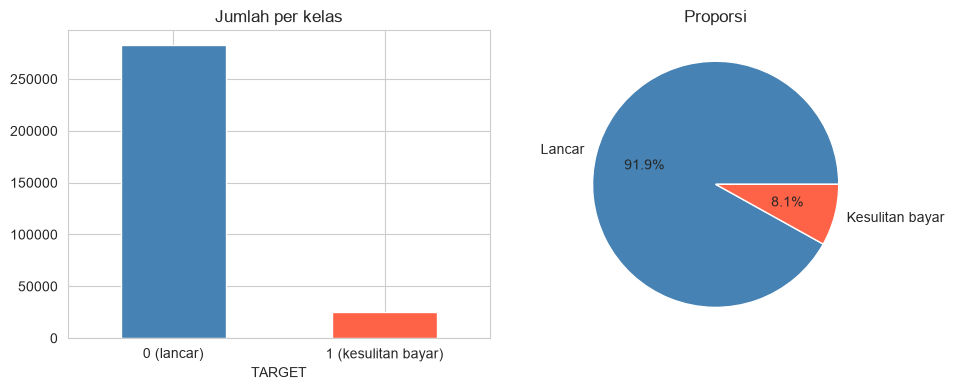

In [12]:
eda = train_fe.copy()
eda['AGE_YEARS'] = -eda['DAYS_BIRTH'] / 365
eda['YEARS_EMPLOYED'] = -eda['DAYS_EMPLOYED'] / 365
base = eda['TARGET'].mean()

# 7.1 Distribusi target
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
eda['TARGET'].value_counts().plot.bar(ax=ax[0], color=['steelblue', 'tomato'])
ax[0].set_title('Jumlah per kelas'); ax[0].set_xticklabels(['0 (lancar)', '1 (kesulitan bayar)'], rotation=0)
ax[1].pie(eda['TARGET'].value_counts(), labels=['Lancar', 'Kesulitan bayar'], autopct='%1.1f%%', colors=['steelblue', 'tomato'])
ax[1].set_title('Proporsi')
save_fig('01_target_distribution'); plt.show()

**Insight – distribusi target**
- Hanya **8,1%** nasabah gagal bayar (91,9% lancar), jadi kelas minoritas kecil.
- **Implikasi:** model yang menebak "semua lancar" akan terlihat akurat padahal tidak berguna. Keberhasilan harus diukur dengan AUC/KS/PR-AUC dan dampak bisnis, bukan *accuracy*.

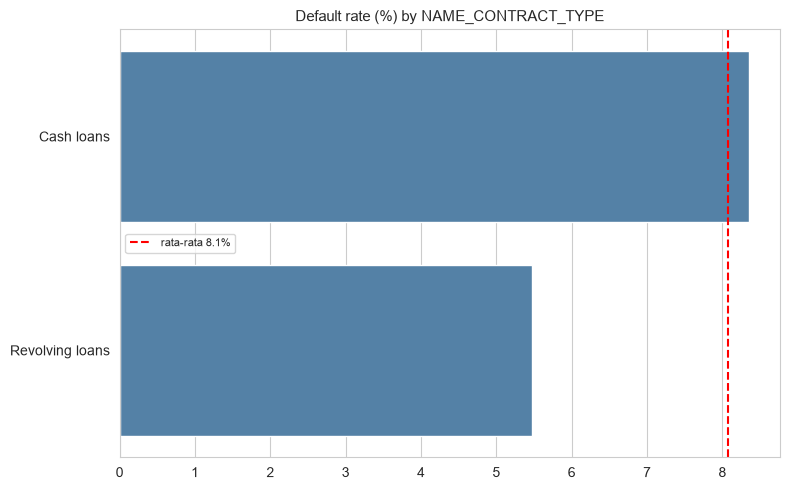

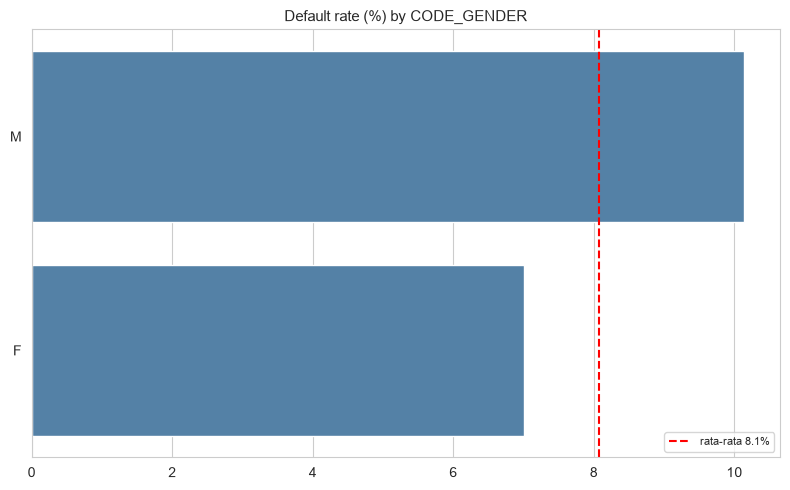

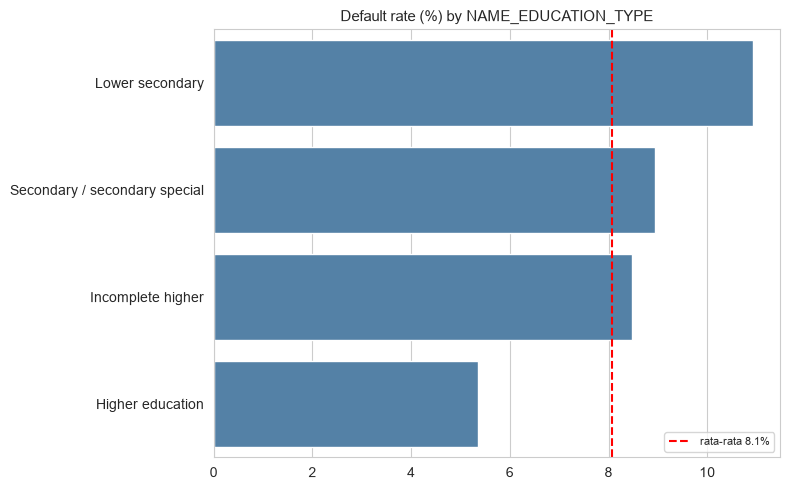

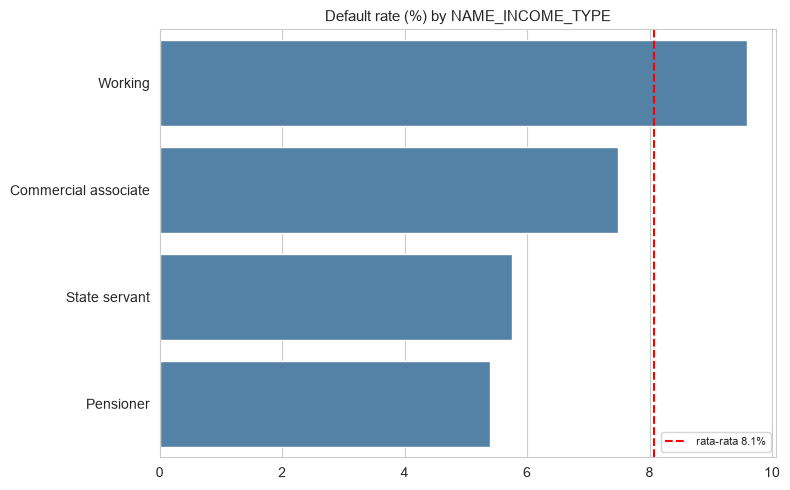

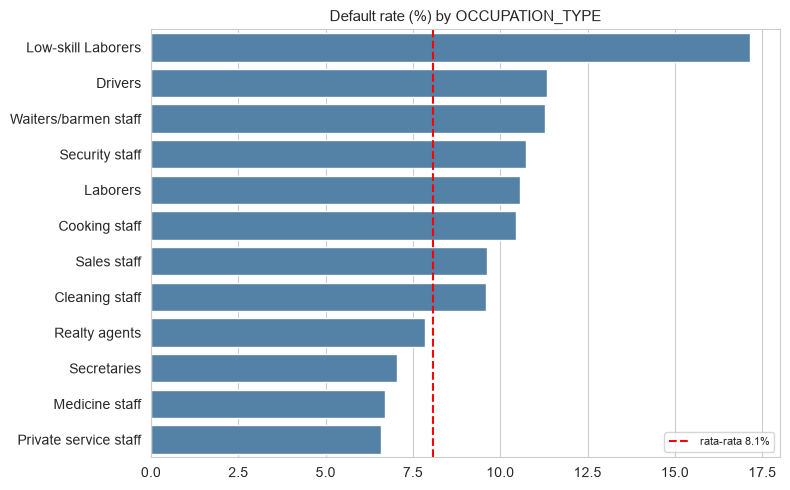

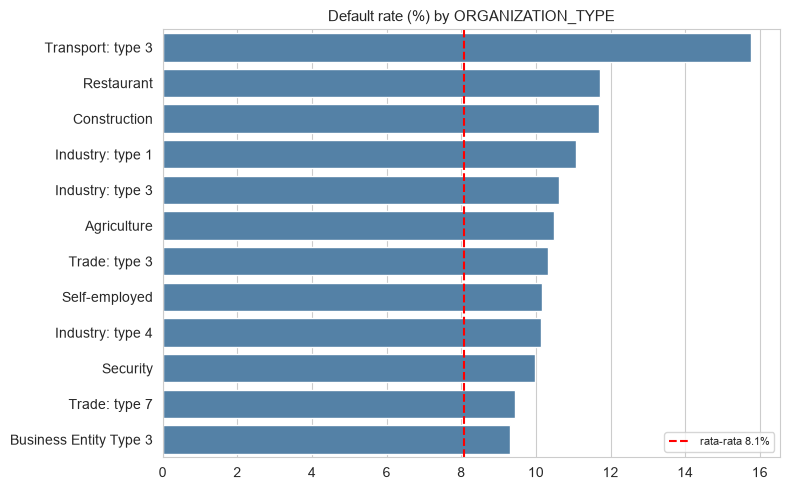

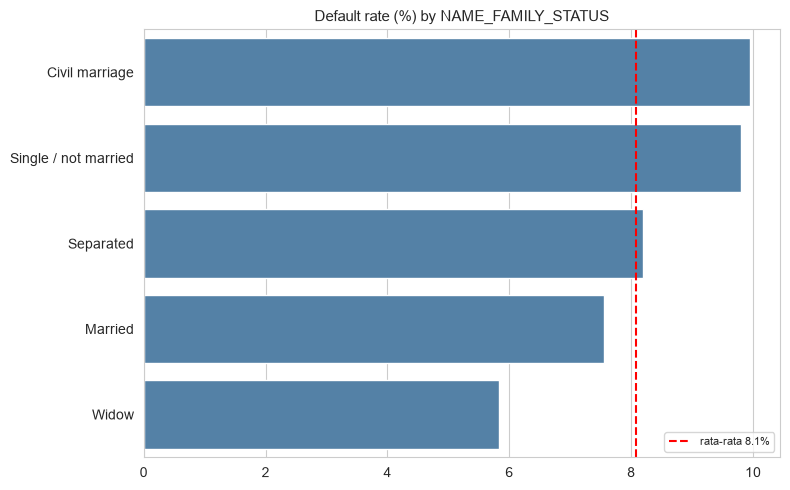

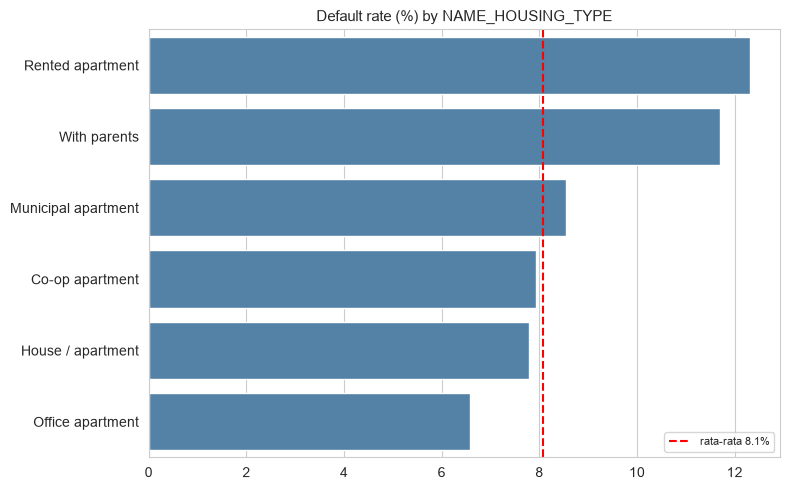

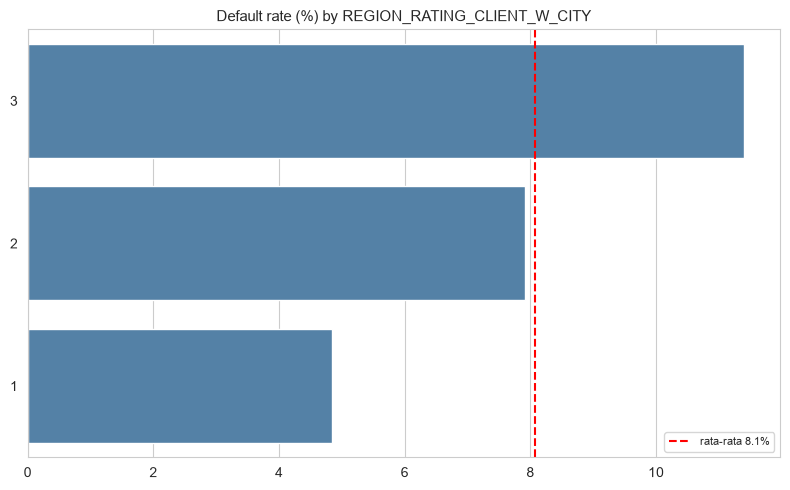

,default_rate_%,count
NAME_CONTRACT_TYPE,,
Cash loans,8.3500,278232
Revolving loans,5.4800,29279


,default_rate_%,count
CODE_GENDER,,
M,10.1400,105059
F,7.0000,202448


,default_rate_%,count
NAME_EDUCATION_TYPE,,
Lower secondary,10.9300,3816
Secondary / secondary special,8.9400,218391
Incomplete higher,8.4800,10277
Higher education,5.3600,74863


,default_rate_%,count
NAME_INCOME_TYPE,,
Working,9.5900,158774
Commercial associate,7.4800,71617
State servant,5.7500,21703
Pensioner,5.3900,55362


,default_rate_%,count
OCCUPATION_TYPE,,
Low-skill Laborers,17.1500,2093
Drivers,11.3300,18603
Waiters/barmen staff,11.2800,1348
Security staff,10.7400,6721
Laborers,10.5800,55186
Cooking staff,10.4400,5946
Sales staff,9.6300,32102
Cleaning staff,9.6100,4653
Realty agents,7.8600,751


In [13]:
# 7.2 Default rate per segmen kategorikal
def plot_default_rate(ax, df, col, min_count=500, top=12):
    t = df.groupby(col, observed=True)['TARGET'].agg(['mean', 'count'])
    t = t[t['count'] >= min_count].sort_values('mean', ascending=False).head(top)
    sns.barplot(x=t['mean'] * 100, y=t.index.astype(str), ax=ax, color='steelblue', orient='h')
    
    # Pastikan variabel `base` sudah didefinisikan sebelumnya di kodemu
    ax.axvline(base * 100, color='red', ls='--', label=f'rata-rata {base:.1%}')
    ax.set_title(f'Default rate (%) by {col}', fontsize=11)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.legend(fontsize=8)
    return t

cols_cat = ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE', 'OCCUPATION_TYPE',
            'ORGANIZATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_RATING_CLIENT_W_CITY']

tabs = {}

# Looping untuk setiap kolom kategori
for c in cols_cat:
    fig, ax = plt.subplots(figsize=(8, 5))
    tabs[c] = plot_default_rate(ax, eda, c)
    
    plt.tight_layout()
    plt.show()

# Menampilkan tabel statistik
for c in ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE', 'OCCUPATION_TYPE']:
    display(tabs[c].assign(mean=lambda d: (d['mean'] * 100).round(2)).rename(columns={'mean': 'default_rate_%'}))

**Implikasi bisnis**
- Risiko cenderung lebih tinggi pada profil dengan **stabilitas pekerjaan, pendidikan, dan tempat tinggal yang lebih rendah**; segmen pekerjaan/industri tertentu perlu verifikasi pendapatan lebih ketat.
- *Revolving loans* lebih rendah risikonya daripada *cash loans*, sehingga produk berlimit kecil bisa menjadi alternatif bagi pemohon berisiko menengah.
- Perbedaan antar gender memang ada di data, tetapi **gender sengaja tidak dipakai di model** (isu fairness/regulasi).
- Ini adalah **korelasi, bukan sebab-akibat**, dan beberapa kategori berukuran kecil (hanya yang n ≥ 500 yang ditampilkan).

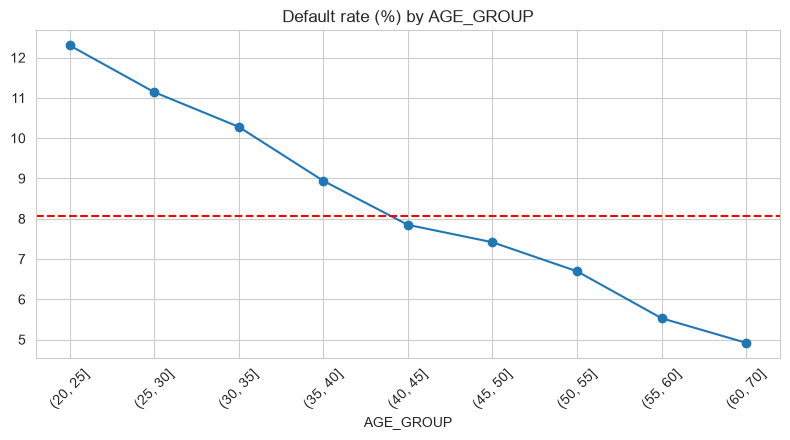

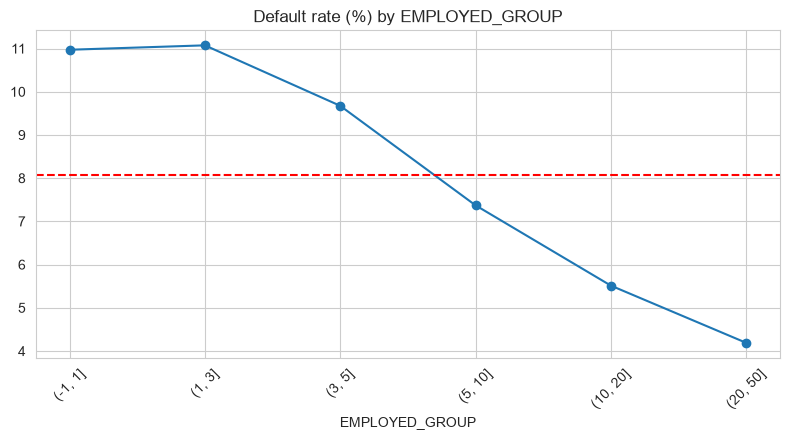

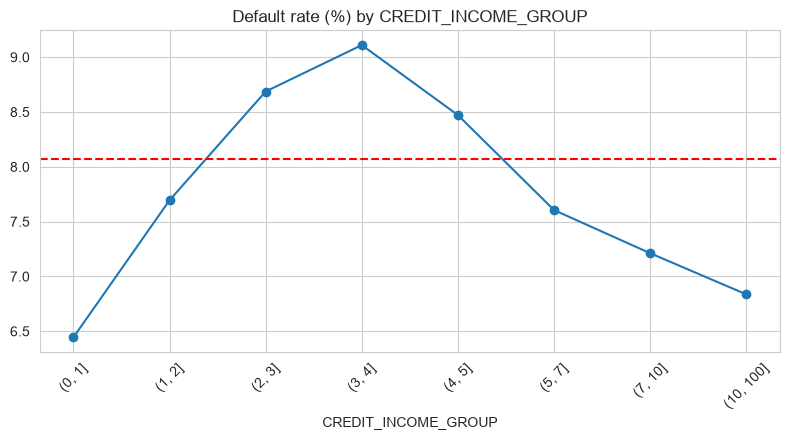

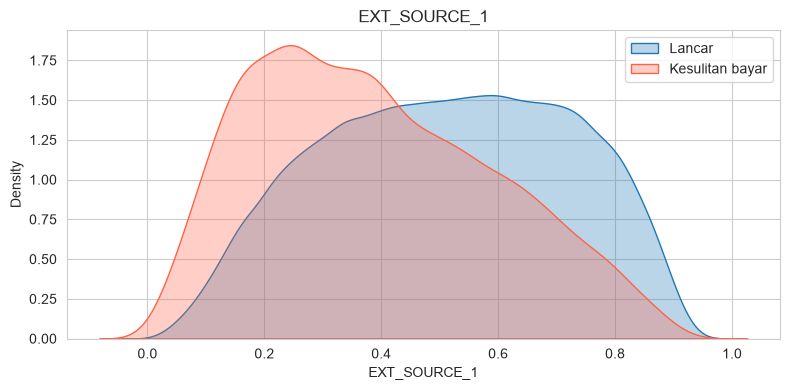

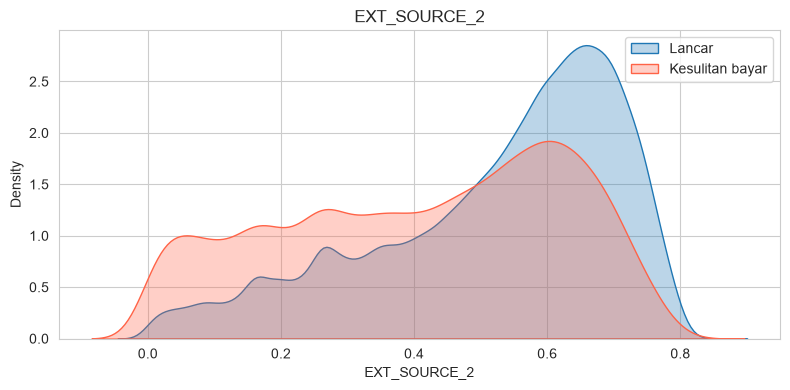

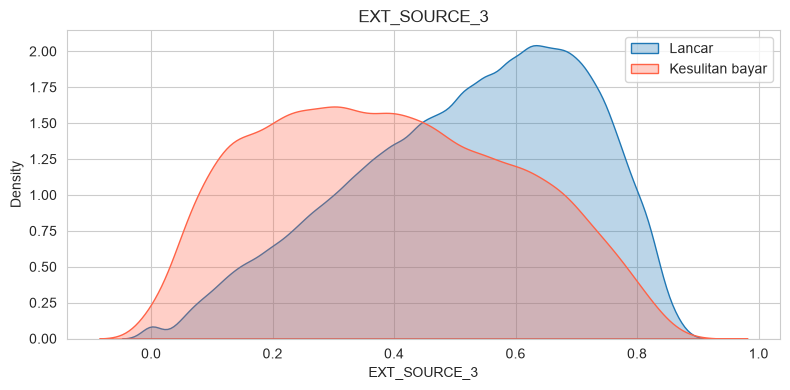

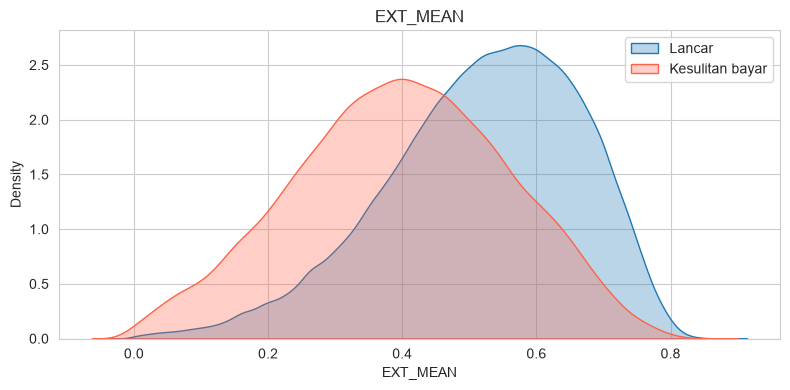

In [14]:
# 7.3 Variabel numerik penting
eda['AGE_GROUP'] = pd.cut(eda['AGE_YEARS'], [20, 25, 30, 35, 40, 45, 50, 55, 60, 70])
eda['EMPLOYED_GROUP'] = pd.cut(eda['YEARS_EMPLOYED'], [-1, 1, 3, 5, 10, 20, 50])
eda['CREDIT_INCOME_GROUP'] = pd.cut(eda['CREDIT_INCOME_RATIO'], [0, 1, 2, 3, 4, 5, 7, 10, 100])

for c in ['AGE_GROUP', 'EMPLOYED_GROUP', 'CREDIT_INCOME_GROUP']:
    fig, ax = plt.subplots(figsize=(8, 4.5)) 
    
    t = eda.groupby(c, observed=True)['TARGET'].mean() * 100
    t.plot(marker='o', ax=ax)
    ax.axhline(base * 100, color='red', ls='--') # Pastikan variabel `base` sudah didefinisikan
    
    ax.set_title(f'Default rate (%) by {c}')
    ax.tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()

for c in EXT + ['EXT_MEAN']:
    fig, ax = plt.subplots(figsize=(8, 4)) 
    
    sns.kdeplot(eda.loc[eda.TARGET == 0, c].dropna(), ax=ax, label='Lancar', fill=True, alpha=.3)
    sns.kdeplot(eda.loc[eda.TARGET == 1, c].dropna(), ax=ax, label='Kesulitan bayar', fill=True, alpha=.3, color='tomato')
    
    ax.set_title(c)
    ax.legend()
    
    plt.tight_layout()
    plt.show()

**Insight – variabel numerik**
- **Umur:** default rate turun hampir monoton, dari ≈**12,3%** (20–25 th) ke ≈**4,9%** (60–70 th). Nasabah muda paling berisiko.
- **Lama bekerja:** ≈**11%** pada <3 tahun turun ke ≈**4,2%** pada >20 tahun → stabilitas kerja menurunkan risiko.
- **Rasio kredit/pendapatan:** polanya **tidak linear** (huruf U terbalik). Puncaknya ≈**9,1%** pada rasio 3–4×, sedangkan rasio sangat rendah (0–1×) ≈6,5% dan sangat tinggi (>10×) ≈6,8%. Rasio tinggi tidak otomatis berarti risiko tinggi, sehingga model perlu bisa menangkap hubungan non-linear (alasan dipakainya *QuantileTransformer* pada model linear).
- **EXT_SOURCE_1/2/3 dan EXT_MEAN:** distribusi nasabah gagal bayar **bergeser jelas ke skor rendah** pada ketiganya; `EXT_MEAN` memisahkan kedua kelas paling baik. Skor eksternal adalah sinyal paling kuat di data aplikasi.

**Implikasi bisnis:** profil "muda + masa kerja pendek + skor eksternal rendah" adalah segmen yang perlu pengawasan lebih ketat. Ketersediaan skor eksternal sangat bernilai, jadi pemohon tanpa skor perlu jalur verifikasi alternatif.

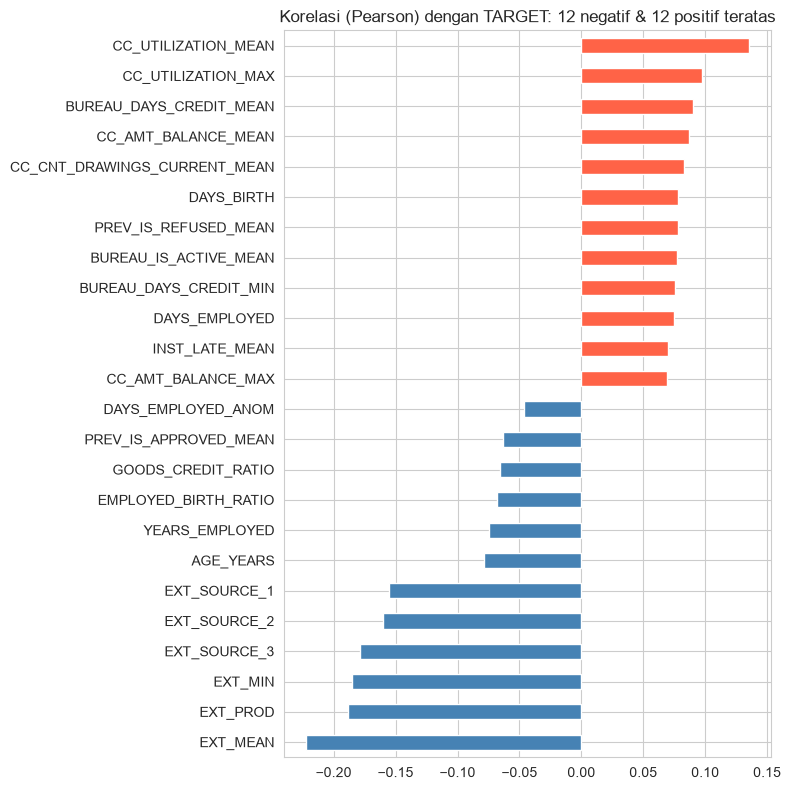

In [15]:
# 7.4 Korelasi dengan TARGET
corr = eda.select_dtypes('number').corr()['TARGET'].drop('TARGET').dropna().sort_values()
top_corr = pd.concat([corr.head(12), corr.tail(12)])
plt.figure(figsize=(8, 8))
top_corr.plot.barh(color=['tomato' if v > 0 else 'steelblue' for v in top_corr])
plt.title('Korelasi (Pearson) dengan TARGET: 12 negatif & 12 positif teratas')
save_fig('05_correlation_target'); plt.show()

**Insight – korelasi dengan TARGET**
- **Negatif terkuat (lebih tinggi → lebih aman):** `EXT_MEAN` (≈ −0,22), `EXT_PROD`, `EXT_MIN`, `EXT_SOURCE_3/2/1` (≈ −0,15 s/d −0,18), lalu umur dan lama bekerja.
- **Positif terkuat (lebih tinggi → lebih berisiko):** `CC_UTILIZATION_MEAN/MAX` (≈ 0,13), `BUREAU_DAYS_CREDIT_MEAN`, `CC_AMT_BALANCE_MEAN`, `PREV_IS_REFUSED_MEAN`, `INST_LATE_MEAN`.
- `DAYS_BIRTH` dan `DAYS_EMPLOYED` bernilai negatif pada data asli, sehingga korelasi positif berarti **lebih muda / baru bekerja → lebih berisiko**. Ini konsisten dengan grafik umur dan masa kerja.
- **Semua korelasi lemah (|r| < 0,25)**: tidak ada satu variabel yang menentukan sendirian. Risiko harus dinilai dari **kombinasi** banyak sinyal.
- Fitur hasil rekayasa (`EXT_MEAN`, `EXT_MIN`, `EXT_PROD`) lebih kuat daripada fitur asalnya, yang menunjukkan *feature engineering* bermanfaat.

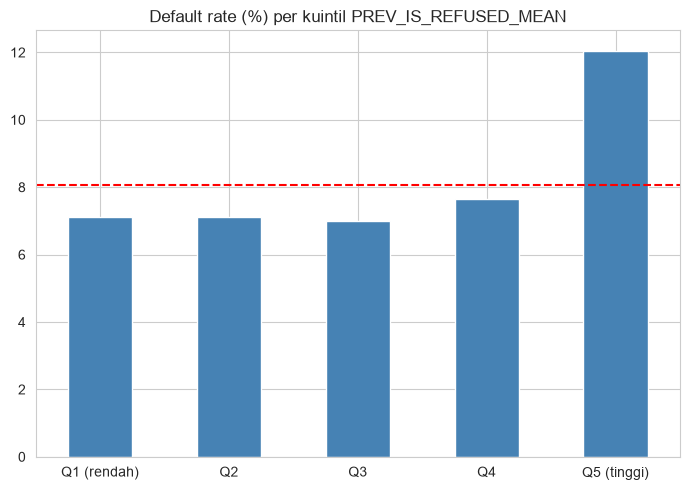

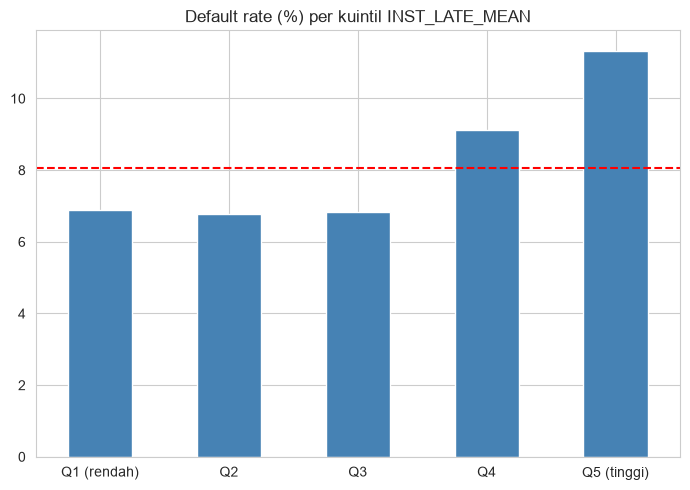

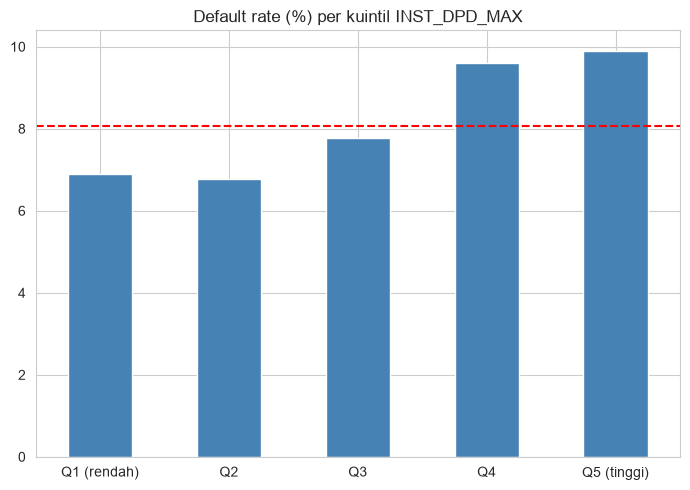

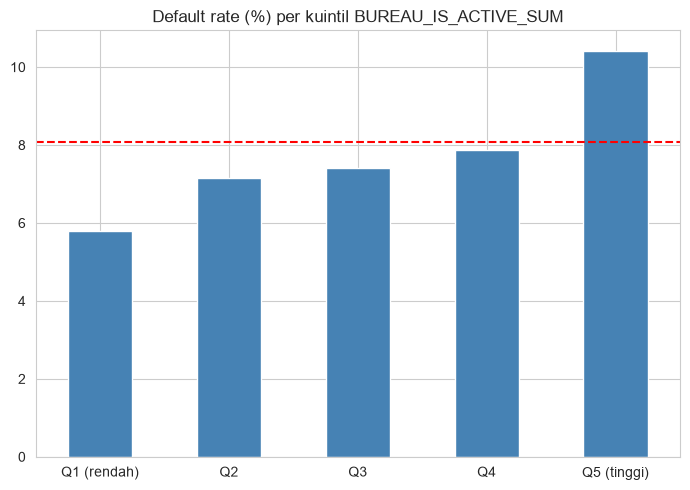

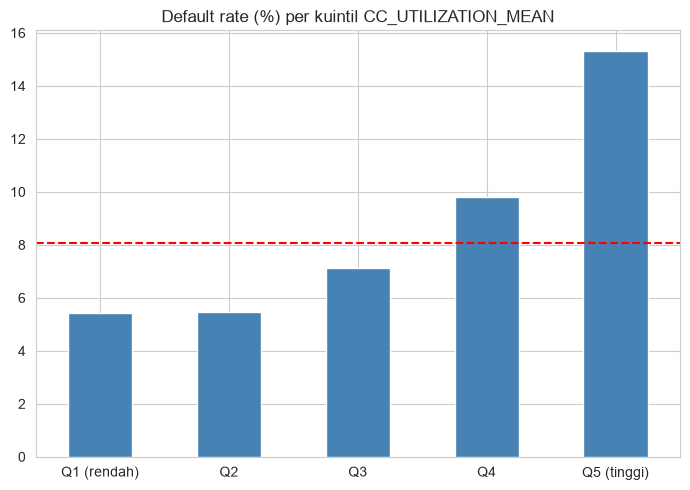

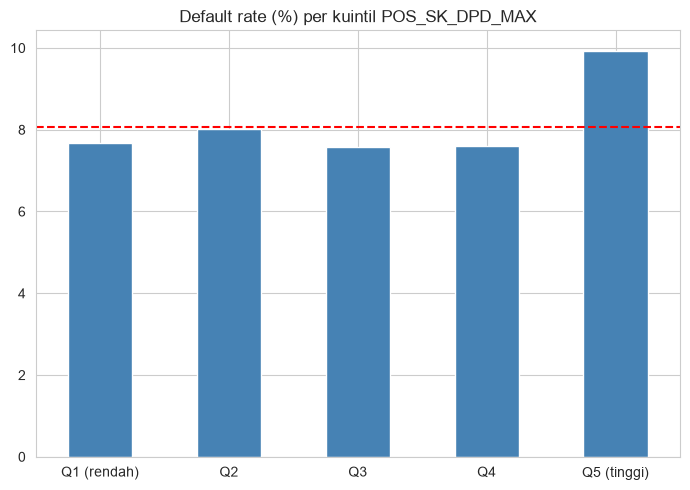

Default rate berdasarkan keberadaan riwayat:
HAS_BUREAU  {0: 10.12, 1: 7.73}
HAS_PREV    {0: 5.96, 1: 8.19}
HAS_INST    {0: 5.98, 1: 8.19}
HAS_POS     {0: 6.66, 1: 8.16}
HAS_CC      {0: 7.84, 1: 8.67}


In [16]:
# 7.5 Fitur riwayat kredit (hasil agregasi)
hist_feats = [c for c in ['PREV_IS_REFUSED_MEAN', 'INST_LATE_MEAN', 'INST_DPD_MAX', 'BUREAU_IS_ACTIVE_SUM',
                          'CC_UTILIZATION_MEAN', 'POS_SK_DPD_MAX'] if c in eda.columns]

# Looping untuk setiap fitur riwayat
for c in hist_feats:
    fig, ax = plt.subplots(figsize=(7, 5)) 
    
    # Proses binning/qcut dan plotting
    q = pd.qcut(eda[c].rank(method='first'), 5, labels=['Q1 (rendah)', 'Q2', 'Q3', 'Q4', 'Q5 (tinggi)'])
    (eda.groupby(q, observed=True)['TARGET'].mean() * 100).plot.bar(ax=ax, color='steelblue')
    
    ax.axhline(base * 100, color='red', ls='--')
    ax.set_title(f'Default rate (%) per kuintil {c}')
    ax.tick_params(axis='x', rotation=0)
    ax.set_xlabel('')
    
    plt.tight_layout()
    plt.show()

print('Default rate berdasarkan keberadaan riwayat:')
for h in ['HAS_BUREAU', 'HAS_PREV', 'HAS_INST', 'HAS_POS', 'HAS_CC']:
    print(f'{h:11s}', (eda.groupby(h)['TARGET'].mean() * 100).round(2).to_dict())

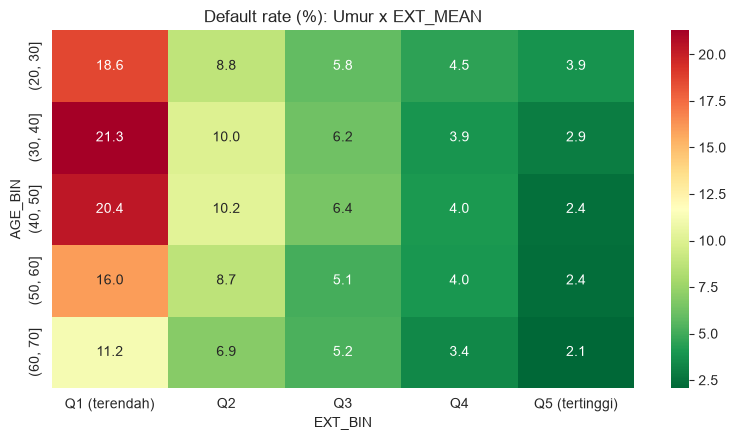

                                  mean   count
DAYS_EMPLOYED_ANOM                            
Bekerja                         0.0866  252137
Anomali (pensiunan/tdk bekerja) 0.0540   55374


In [17]:
# 7.6 Interaksi: umur x kualitas skor eksternal
eda['AGE_BIN'] = pd.cut(eda['AGE_YEARS'], [20, 30, 40, 50, 60, 70])
eda['EXT_BIN'] = pd.qcut(eda['EXT_MEAN'], 5, labels=['Q1 (terendah)', 'Q2', 'Q3', 'Q4', 'Q5 (tertinggi)'])
pv = eda.pivot_table(index='AGE_BIN', columns='EXT_BIN', values='TARGET', aggfunc='mean', observed=True) * 100
plt.figure(figsize=(8, 4.5)); sns.heatmap(pv, annot=True, fmt='.1f', cmap='RdYlGn_r')
plt.title('Default rate (%): Umur x EXT_MEAN'); save_fig('07_heatmap_age_ext'); plt.show()

# Pensiunan (anomali DAYS_EMPLOYED) vs lainnya
print((eda.groupby('DAYS_EMPLOYED_ANOM')['TARGET'].agg(['mean', 'count']).rename(index={0: 'Bekerja', 1: 'Anomali (pensiunan/tdk bekerja)'})))

**Insight – interaksi umur × skor eksternal**
- `EXT_MEAN` **jauh lebih dominan** daripada umur. Di kuintil skor terendah (Q1), default rate **16–21%** pada usia 30–60, sedangkan di kuintil tertinggi (Q5) hanya **±2–4%**. Itu selisih sekitar 5–10×.
- Saat skor eksternal rendah, kelompok **usia 30–50** paling berisiko (≈**20–21%**), sementara usia 60–70 ≈ 11%. Efek "muda = berisiko" terutama muncul pada skor menengah–tinggi.
- **Nasabah dengan flag anomali `DAYS_EMPLOYED`** (kemungkinan pensiunan/tidak bekerja): default rate **5,40%** vs yang bekerja **8,66%**. Karena itu flag ini dipertahankan sebagai fitur.

**Implikasi bisnis:** kombinasi *skor eksternal rendah + usia produktif* adalah segmen paling berisiko dan layak mendapat verifikasi tambahan atau limit lebih rendah.

## Machine Learning Implementation & Evaluation

In [18]:
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
                             confusion_matrix, classification_report, f1_score)
from scipy.stats import loguniform, randint, uniform
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

TARGET, ID = 'TARGET', 'SK_ID_CURR'
SENSITIVE = ['CODE_GENDER']

y = train_fe[TARGET].reset_index(drop=True)
all_X = pd.concat([train_fe.drop(columns=[TARGET]), test_fe], keys=['train', 'test'])
all_X = all_X.drop(columns=[ID] + SENSITIVE)

cat_cols = all_X.select_dtypes('object').columns.tolist()
all_X = pd.get_dummies(all_X, columns=cat_cols, dtype='int8')
all_X.columns = [re.sub(r'[^0-9a-zA-Z_]', '_', c) for c in all_X.columns]
assert all_X.columns.is_unique, 'Nama kolom duplikat setelah sanitasi'
all_X = all_X.replace([np.inf, -np.inf], np.nan)
f64 = all_X.select_dtypes('float64').columns
all_X[f64] = all_X[f64].astype('float32')

X = all_X.loc['train'].reset_index(drop=True)
X_test = all_X.loc['test'].reset_index(drop=True)
test_ids = test_fe[ID].reset_index(drop=True)
print('Matrix fitur:', X.shape, '| test:', X_test.shape)

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f'Train {X_train.shape} (bad rate {y_train.mean():.2%}) | Valid {X_valid.shape} (bad rate {y_valid.mean():.2%})')
del all_X, train_app, test_app; gc.collect()

Matrix fitur: (307511, 269) | test: (48744, 269)
Train (246008, 269) (bad rate 8.07%) | Valid (61503, 269) (bad rate 8.07%)


20

In [19]:
def ks_stat(y_true, p):
    fpr, tpr, _ = roc_curve(y_true, p)
    return float((tpr - fpr).max())

def score_all(y_true, p):
    auc = roc_auc_score(y_true, p)
    return {'AUC': auc, 'Gini': 2 * auc - 1, 'KS': ks_stat(y_true, p), 'PR_AUC': average_precision_score(y_true, p)}

# Subsample untuk tuning (percepat)
TUNE_N = 80_000
tune_idx = X_train.sample(n=min(TUNE_N, len(X_train)), random_state=RANDOM_STATE).index
X_tune, y_tune = X_train.loc[tune_idx], y_train.loc[tune_idx]
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
N_ITER = 8   # naikkan kalau waktu cukup

def lin_pre():
    return [('imp', SimpleImputer(strategy='median', keep_empty_features=True)),
            ('qt', QuantileTransformer(n_quantiles=200, output_distribution='normal', subsample=100_000, random_state=RANDOM_STATE))]
def tree_pre():
    return [('imp', SimpleImputer(strategy='median', keep_empty_features=True))]

models = {
    'Logistic Regression': dict(
        pipe=Pipeline(lin_pre() + [('clf', LogisticRegression(solver='liblinear', max_iter=300, random_state=RANDOM_STATE))]),
        dist={'clf__C': loguniform(1e-3, 10), 'clf__penalty': ['l1', 'l2'], 'clf__class_weight': [None, 'balanced']},
        n_iter=N_ITER, jobs=-1),
    'Decision Tree': dict(
        pipe=Pipeline(tree_pre() + [('clf', DecisionTreeClassifier(random_state=RANDOM_STATE))]),
        dist={'clf__max_depth': randint(3, 12), 'clf__min_samples_leaf': randint(50, 500),
              'clf__criterion': ['gini', 'entropy'], 'clf__class_weight': [None, 'balanced']},
        n_iter=N_ITER, jobs=-1),
    'Random Forest': dict(
        pipe=Pipeline(tree_pre() + [('clf', RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE))]),
        dist={'clf__n_estimators': [150, 250], 'clf__max_depth': [6, 8, 10, 12], 'clf__min_samples_leaf': randint(20, 200),
              'clf__max_features': ['sqrt', 0.3], 'clf__class_weight': ['balanced_subsample', None]},
        n_iter=6, jobs=1),
    'LightGBM': dict(
        pipe=Pipeline([('clf', LGBMClassifier(importance_type='gain', subsample_freq=1, n_jobs=-1, verbose=-1, random_state=RANDOM_STATE))]),
        dist={'clf__n_estimators': randint(200, 600), 'clf__learning_rate': loguniform(0.02, 0.1),
              'clf__num_leaves': randint(15, 64), 'clf__max_depth': [-1, 6, 8], 'clf__min_child_samples': randint(50, 300),
              'clf__subsample': uniform(0.7, 0.3), 'clf__colsample_bytree': uniform(0.4, 0.5),
              'clf__reg_alpha': loguniform(1e-3, 10), 'clf__reg_lambda': loguniform(1e-3, 10),
              'clf__scale_pos_weight': [1, 3, 11]},
        n_iter=N_ITER, jobs=1),
    'XGBoost': dict(
        pipe=Pipeline([('clf', XGBClassifier(tree_method='hist', eval_metric='auc', n_jobs=-1, random_state=RANDOM_STATE))]),
        dist={'clf__n_estimators': randint(200, 600), 'clf__learning_rate': loguniform(0.02, 0.1),
              'clf__max_depth': randint(3, 8), 'clf__min_child_weight': randint(1, 20),
              'clf__subsample': uniform(0.7, 0.3), 'clf__colsample_bytree': uniform(0.4, 0.5),
              'clf__reg_alpha': loguniform(1e-3, 10), 'clf__reg_lambda': loguniform(1e-3, 10),
              'clf__scale_pos_weight': [1, 3, 11]},
        n_iter=N_ITER, jobs=1),
}

results, fitted, val_proba, best_params_all = [], {}, {}, {}

# Baseline pembanding
dummy = DummyClassifier(strategy='prior').fit(X_train, y_train)
base_scores = score_all(y_valid, dummy.predict_proba(X_valid)[:, 1])
print('Baseline (prior) AUC:', round(base_scores['AUC'], 4))

# Baseline Logistic Regression tanpa tuning (default)
t0 = time.time()
lr_base = Pipeline(lin_pre() + [('clf', LogisticRegression(solver='liblinear', max_iter=300, random_state=RANDOM_STATE))]).fit(X_train, y_train)
p_tr, p_va = lr_base.predict_proba(X_train)[:, 1], lr_base.predict_proba(X_valid)[:, 1]
results.append({'Model': 'Logistic Regression (default)', 'CV AUC (tune)': np.nan, 'Train AUC': roc_auc_score(y_train, p_tr),
                'Valid AUC': roc_auc_score(y_valid, p_va), **{k: v for k, v in score_all(y_valid, p_va).items() if k != 'AUC'},
                'Fit time (s)': time.time() - t0})
fitted['Logistic Regression (default)'], val_proba['Logistic Regression (default)'] = lr_base, p_va
print(results[-1])

Baseline (prior) AUC: 0.5
{'Model': 'Logistic Regression (default)', 'CV AUC (tune)': nan, 'Train AUC': 0.7695988805270622, 'Valid AUC': 0.7693229485666708, 'Gini': 0.5386458971333417, 'KS': 0.40535914192513256, 'PR_AUC': 0.2599302030219671, 'Fit time (s)': 231.7110788822174}


In [20]:
# Mode cepat: perkecil subsample & ruang pencarian
TUNE_N = 30_000
tune_idx = X_train.sample(n=TUNE_N, random_state=RANDOM_STATE).index
X_tune, y_tune = X_train.loc[tune_idx], y_train.loc[tune_idx]

# Logistic Regression: l2 saja + solver lbfgs (jauh lebih cepat dari liblinear+l1)
models['Logistic Regression']['pipe'].set_params(clf__solver='lbfgs', clf__max_iter=200)
models['Logistic Regression']['dist']['clf__penalty'] = ['l2']
models['Logistic Regression']['n_iter'] = 5

# Random Forest: lebih kecil
models['Random Forest']['pipe'].set_params(clf__n_estimators=100)
models['Random Forest']['dist']['clf__n_estimators'] = [100]
models['Random Forest']['dist']['clf__max_depth'] = [6, 8, 10]
models['Random Forest']['n_iter'] = 3

for m in ['Decision Tree', 'LightGBM', 'XGBoost']:
    models[m]['n_iter'] = 5

## EVALUASI HASIL MODEL

,Model,CV AUC (tune),Train AUC,Valid AUC,Gini,KS,PR_AUC,Fit time (s),Overfit gap (Train-Valid AUC)
0,Logistic Regression (default),NaN,0.7696,0.7693,0.5386,0.4054,0.2599,231.7111,0.0003


Model terbaik: Logistic Regression (default)
Best params: default


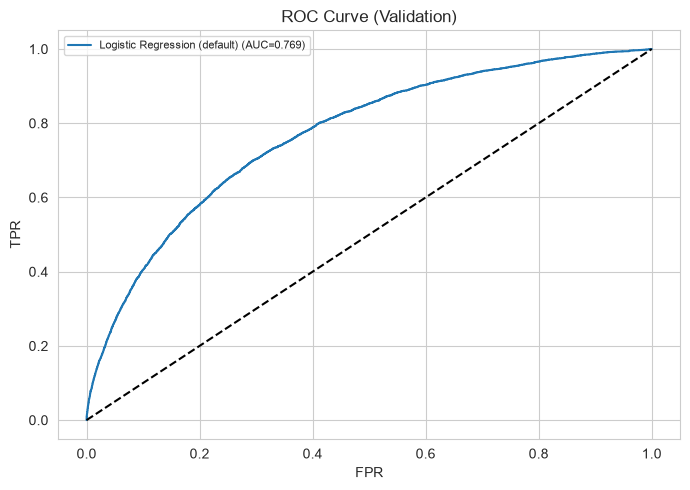

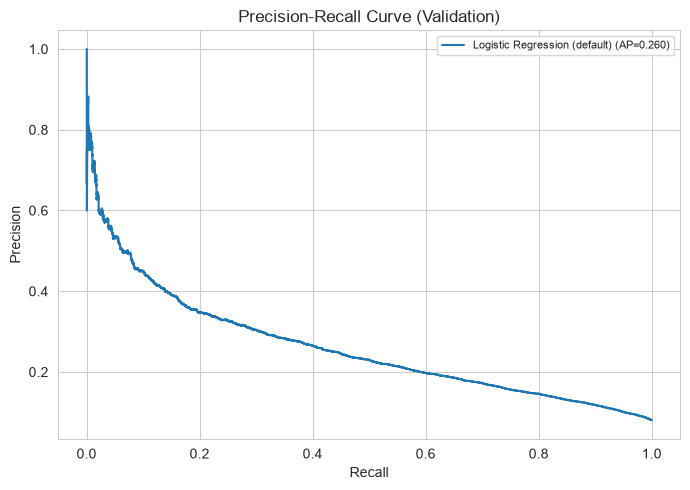

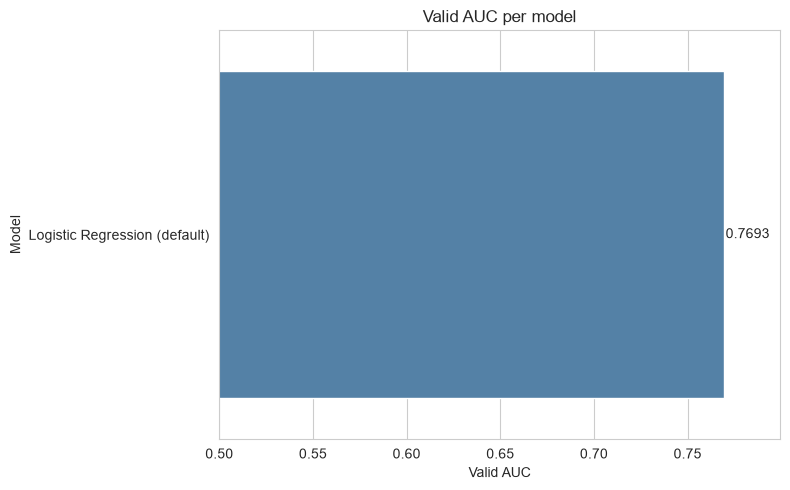

In [22]:
results_df = pd.DataFrame(results).sort_values('Valid AUC', ascending=False).reset_index(drop=True)
results_df['Overfit gap (Train-Valid AUC)'] = results_df['Train AUC'] - results_df['Valid AUC']
display(results_df)

best_name = results_df.loc[0, 'Model']
best_model = fitted[best_name]
best_val_proba = val_proba[best_name]
print('Model terbaik:', best_name)
print('Best params:', best_params_all.get(best_name, 'default'))

# --- Gambar 1: ROC Curve ---
fig, ax = plt.subplots(figsize=(7, 5))
for n, p in val_proba.items():
    fpr, tpr, _ = roc_curve(y_valid, p)
    ax.plot(fpr, tpr, label=f'{n} (AUC={roc_auc_score(y_valid, p):.3f})')
ax.plot([0, 1], [0, 1], 'k--')
ax.set_title('ROC Curve (Validation)')
ax.set_xlabel('FPR')
ax.set_ylabel('TPR')
ax.legend(fontsize=8)
plt.tight_layout()
# save_fig('08_model_comparison_roc')
plt.show()

# --- Gambar 2: Precision-Recall Curve ---
fig, ax = plt.subplots(figsize=(7, 5))
for n, p in val_proba.items():
    pr, rc, _ = precision_recall_curve(y_valid, p)
    ax.plot(rc, pr, label=f'{n} (AP={average_precision_score(y_valid, p):.3f})')
ax.set_title('Precision-Recall Curve (Validation)')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.legend(fontsize=8)
plt.tight_layout()
# save_fig('08_model_comparison_pr')
plt.show()

# --- Gambar 3: Barplot Valid AUC per model ---
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=results_df, y='Model', x='Valid AUC', ax=ax, color='steelblue', orient='h')
ax.set_xlim(0.5, results_df['Valid AUC'].max() + 0.03)
ax.set_title('Valid AUC per model')
for i, v in enumerate(results_df['Valid AUC']): 
    ax.text(v + 0.001, i, f'{v:.4f}', va='center')
plt.tight_layout()
# save_fig('08_model_comparison_bar')
plt.show()

Logistic Regression (default): AUC valid = 0.7693 (95% CI bootstrap 0.7627 - 0.7763)

Threshold optimal-F1 = 0.166
                 precision    recall  f1-score   support

         Lancar      0.945     0.903     0.924     56538
Kesulitan bayar      0.266     0.399     0.320      4965

       accuracy                          0.863     61503
      macro avg      0.606     0.651     0.622     61503
   weighted avg      0.890     0.863     0.875     61503



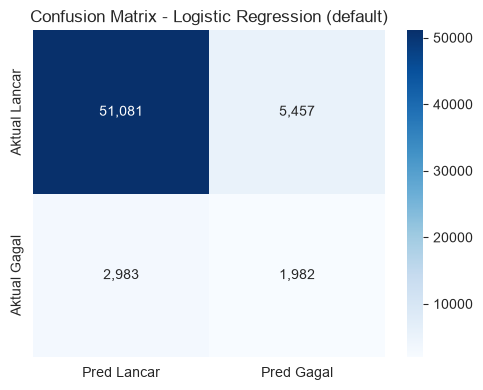

In [23]:
# Stabilitas estimasi: bootstrap 95% CI AUC pada validation
rng = np.random.default_rng(RANDOM_STATE)
yv = y_valid.values
boot = []
for _ in range(200):
    idx = rng.integers(0, len(yv), len(yv))
    boot.append(roc_auc_score(yv[idx], best_val_proba[idx]))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f'{best_name}: AUC valid = {roc_auc_score(yv, best_val_proba):.4f} (95% CI bootstrap {lo:.4f} - {hi:.4f})')

# Confusion matrix & classification report pada threshold optimal-F1
prec, rec, thr = precision_recall_curve(y_valid, best_val_proba)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
thr_f1 = thr[np.argmax(f1s)]
pred = (best_val_proba >= thr_f1).astype(int)
print(f'\nThreshold optimal-F1 = {thr_f1:.3f}')
print(classification_report(y_valid, pred, target_names=['Lancar', 'Kesulitan bayar'], digits=3))

cm = confusion_matrix(y_valid, pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', xticklabels=['Pred Lancar', 'Pred Gagal'], yticklabels=['Aktual Lancar', 'Aktual Gagal'])
plt.title(f'Confusion Matrix - {best_name}'); save_fig('09_confusion_matrix'); plt.show()

,n,bad,bad_rate,avg_score,lift,cum_bad_capture
risk_decile,,,,,,
1,6151,69,0.0112,0.0092,0.1390,1.0000
2,6150,123,0.0200,0.0177,0.2477,0.9861
3,6150,143,0.0233,0.0257,0.2880,0.9613
4,6150,198,0.0322,0.0346,0.3988,0.9325
5,6151,283,0.0460,0.0455,0.5699,0.8926
6,6150,370,0.0602,0.0594,0.7453,0.8356
7,6150,465,0.0756,0.0777,0.9366,0.7611
8,6150,643,0.1046,0.1041,1.2951,0.6675
9,6150,929,0.1511,0.1490,1.8712,0.5380


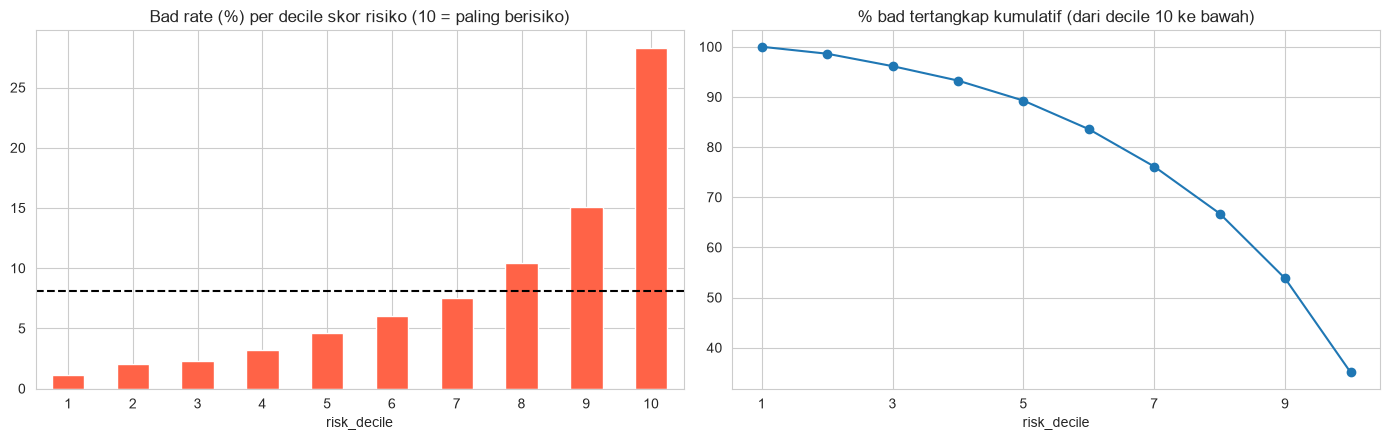

In [24]:
# Decile / lift analysis
vd = pd.DataFrame({'y': y_valid.values, 'p': best_val_proba})
vd['risk_decile'] = pd.qcut(vd['p'].rank(method='first'), 10, labels=range(1, 11))   # 10 = skor paling berisiko
dec = vd.groupby('risk_decile', observed=True).agg(n=('y', 'size'), bad=('y', 'sum'), bad_rate=('y', 'mean'), avg_score=('p', 'mean'))
dec['lift'] = dec['bad_rate'] / vd['y'].mean()
dec['cum_bad_capture'] = dec['bad'][::-1].cumsum()[::-1] / dec['bad'].sum()   # kumulatif dari decile 10 ke bawah
display(dec)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
(dec['bad_rate'] * 100).plot.bar(ax=ax[0], color='tomato'); ax[0].axhline(vd['y'].mean() * 100, color='k', ls='--')
ax[0].set_title('Bad rate (%) per decile skor risiko (10 = paling berisiko)'); ax[0].tick_params(axis='x', rotation=0)
(dec['cum_bad_capture'] * 100).plot(marker='o', ax=ax[1]); ax[1].set_title('% bad tertangkap kumulatif (dari decile 10 ke bawah)')
save_fig('10_decile_analysis'); plt.show()

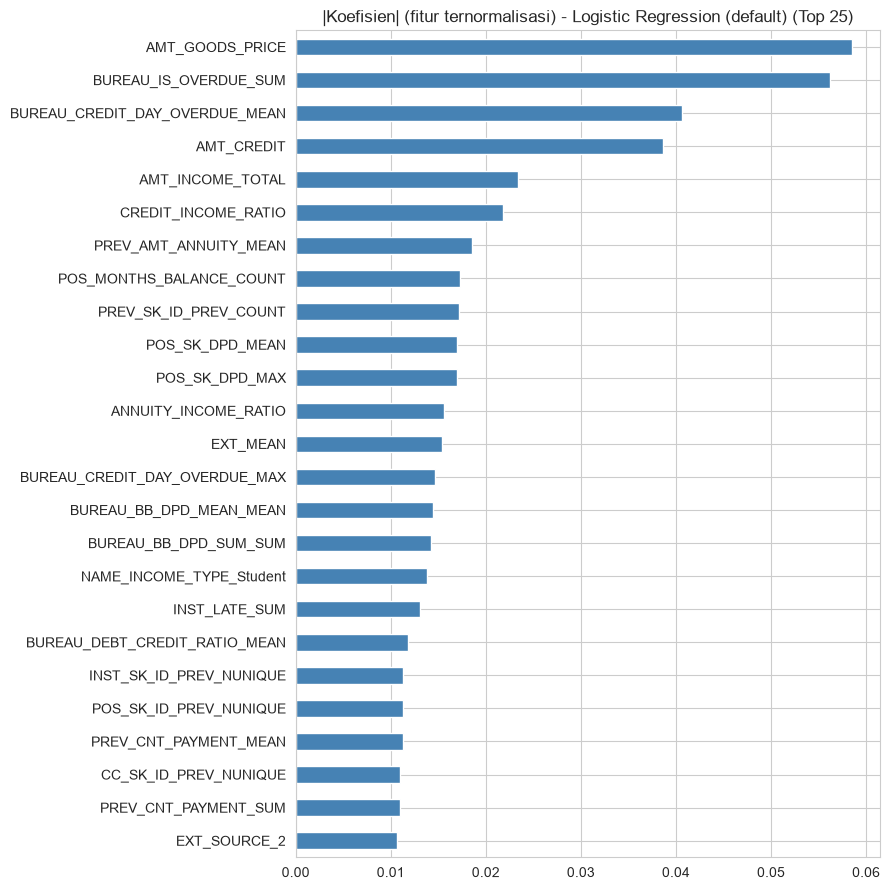

,relative_importance
AMT_GOODS_PRICE,0.0585
BUREAU_IS_OVERDUE_SUM,0.0562
BUREAU_CREDIT_DAY_OVERDUE_MEAN,0.0406
AMT_CREDIT,0.0386
AMT_INCOME_TOTAL,0.0234
CREDIT_INCOME_RATIO,0.0218
PREV_AMT_ANNUITY_MEAN,0.0185
POS_MONTHS_BALANCE_COUNT,0.0173
PREV_SK_ID_PREV_COUNT,0.0172
POS_SK_DPD_MEAN,0.0170


In [25]:
# Feature importance / koefisien model terbaik
clf = best_model.named_steps['clf']
if hasattr(clf, 'feature_importances_'):
    imp = pd.Series(clf.feature_importances_, index=X_train.columns)
    imp_title = 'Feature importance'
else:
    imp = pd.Series(np.abs(clf.coef_[0]), index=X_train.columns)
    imp_title = '|Koefisien| (fitur ternormalisasi)'
imp = (imp / imp.sum()).sort_values(ascending=False)
plt.figure(figsize=(9, 9))
imp.head(25)[::-1].plot.barh(color='steelblue')
plt.title(f'{imp_title} - {best_name} (Top 25)'); save_fig('11_feature_importance'); plt.show()
display(imp.head(15).to_frame('relative_importance'))

In [26]:
# SHAP (opsional; hanya untuk model tree-based) - arah pengaruh tiap fitur
try:
    import shap
    if best_name in ['LightGBM', 'XGBoost', 'Random Forest', 'Decision Tree']:
        Xs = best_model[:-1].transform(X_valid.sample(5000, random_state=RANDOM_STATE)) if len(best_model.steps) > 1 \
            else X_valid.sample(5000, random_state=RANDOM_STATE)
        Xs = pd.DataFrame(Xs, columns=X_valid.columns)
        sv = shap.TreeExplainer(clf).shap_values(Xs)
        if isinstance(sv, list): sv = sv[1]
        if getattr(sv, 'ndim', 2) == 3: sv = sv[:, :, 1]
        shap.summary_plot(sv, Xs, max_display=20, show=False)
        save_fig('12_shap_summary'); plt.show()
except Exception as e:
    print('SHAP dilewati:', e)

## Business Recommendation

In [28]:
LGD, MARGIN = 0.60, 0.10

vdf = pd.DataFrame({'y': y_valid.values, 'p': best_val_proba, 'credit': X_valid['AMT_CREDIT'].values})

def simulate(vdf, reject_rate, lgd=LGD, margin=MARGIN):
    thr = np.inf if reject_rate == 0 else np.quantile(vdf['p'], 1 - reject_rate)
    ap = vdf[vdf['p'] < thr]
    loss = (ap['credit'] * ap['y']).sum() * lgd
    rev = (ap['credit'] * (1 - ap['y'])).sum() * margin
    return {'reject_rate': reject_rate, 'approval_rate': len(ap) / len(vdf), 'bad_rate': ap['y'].mean(),
            'expected_loss': loss, 'revenue': rev, 'profit': rev - loss,
            'bad_caught': 1 - ap['y'].sum() / vdf['y'].sum(),
            'good_rejected': 1 - (ap['y'] == 0).sum() / (vdf['y'] == 0).sum()}

sweep = pd.DataFrame([simulate(vdf, r) for r in np.arange(0, 0.61, 0.01)])
baseline = sweep.iloc[0]
opt = sweep.loc[sweep['profit'].idxmax()]
cons = sweep.loc[(sweep['reject_rate'] - 0.10).abs().idxmin()]

cmp_df = pd.DataFrame({'Baseline (approve semua)': baseline, 'Model - konservatif (reject 10%)': cons, 'Model - optimal profit': opt}).T
cmp_df = cmp_df[['reject_rate', 'approval_rate', 'bad_rate', 'expected_loss', 'revenue', 'profit', 'bad_caught', 'good_rejected']]
display(cmp_df.style.format({'reject_rate': '{:.0%}', 'approval_rate': '{:.1%}', 'bad_rate': '{:.2%}', 'expected_loss': '{:,.0f}',
                             'revenue': '{:,.0f}', 'profit': '{:,.0f}', 'bad_caught': '{:.1%}', 'good_rejected': '{:.1%}'}))

impact = {
    'reject_rate': float(opt['reject_rate']), 'approval_rate': float(opt['approval_rate']),
    'bad_rate_base': float(baseline['bad_rate']), 'bad_rate_model': float(opt['bad_rate']),
    'bad_rate_reduction_pct': float(1 - opt['bad_rate'] / baseline['bad_rate']),
    'loss_base': float(baseline['expected_loss']), 'loss_model': float(opt['expected_loss']),
    'loss_reduction_pct': float(1 - opt['expected_loss'] / baseline['expected_loss']),
    'profit_base': float(baseline['profit']), 'profit_model': float(opt['profit']),
    'profit_uplift_pct': float(opt['profit'] / baseline['profit'] - 1),
    'bad_caught': float(opt['bad_caught']), 'good_rejected': float(opt['good_rejected']),
}
print(f"Pada reject rate optimal {impact['reject_rate']:.0%} (approval {impact['approval_rate']:.1%}):")
print(f"  Bad rate approved : {impact['bad_rate_base']:.2%} -> {impact['bad_rate_model']:.2%}  (turun {impact['bad_rate_reduction_pct']:.1%})")
print(f"  Expected loss     : turun {impact['loss_reduction_pct']:.1%}")
print(f"  Net profit        : naik {impact['profit_uplift_pct']:.1%}")
print(f"  Bad tertangkap    : {impact['bad_caught']:.1%} | Nasabah baik ikut ditolak: {impact['good_rejected']:.1%}")

,reject_rate,approval_rate,bad_rate,expected_loss,revenue,profit,bad_caught,good_rejected
Baseline (approve semua),0%,100.0%,8.07%,"1,665,214,629","3,398,972,243","1,733,757,614",0.0%,0.0%
Model - konservatif (reject 10%),10%,90.0%,5.82%,"1,120,462,705","3,164,899,710","2,044,437,005",35.1%,7.8%
Model - optimal profit,17%,83.0%,4.97%,"893,345,514","2,965,006,654","2,071,661,139",48.9%,14.2%


Pada reject rate optimal 17% (approval 83.0%):
  Bad rate approved : 8.07% -> 4.97%  (turun 38.5%)
  Expected loss     : turun 46.4%
  Net profit        : naik 19.5%
  Bad tertangkap    : 48.9% | Nasabah baik ikut ditolak: 14.2%


- Dengan menolak 17% pemohon berisiko tertinggi, kerugian turun hampir separuh dan profit bersih naik **19,5%**.
- **Kurva profit relatif datar di sekitar titik optimal.** Dari reject 10% ke 17%, profit hanya naik ±1,6 poin persen (±27 juta), sementara jumlah nasabah baik yang ikut ditolak hampir berlipat (7,8% → 14,2%). Skenario konservatif sudah menangkap hampir seluruh manfaatnya dengan dampak volume lebih kecil.

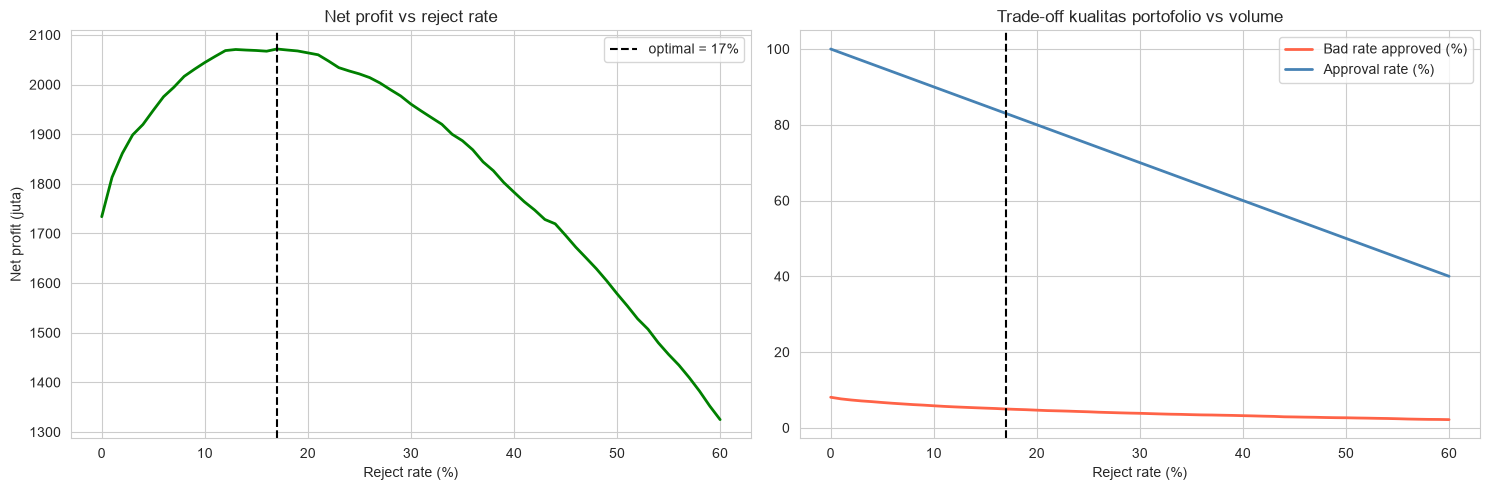

,LGD,Margin,optimal_reject_rate,profit_uplift_%,loss_reduction_%
0,0.4000,0.0500,0.2000,52.2020,51.3778
1,0.4000,0.1000,0.1000,5.6402,32.7136
2,0.4000,0.1500,0.0400,1.4121,16.0293
3,0.6000,0.0500,0.3600,"1,908.7884",70.4729
4,0.6000,0.1000,0.1800,19.3710,48.0240
5,0.6000,0.1500,0.1000,5.6402,32.7136
6,0.8000,0.0500,0.4400,NaN,77.8509
7,0.8000,0.1000,0.2000,52.2020,51.3778
8,0.8000,0.1500,0.1200,13.8329,37.4446


In [29]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].plot(sweep['reject_rate'] * 100, sweep['profit'] / 1e6, color='green', lw=2)
ax[0].axvline(opt['reject_rate'] * 100, color='k', ls='--', label=f"optimal = {opt['reject_rate']:.0%}")
ax[0].set_xlabel('Reject rate (%)'); ax[0].set_ylabel('Net profit (juta)'); ax[0].set_title('Net profit vs reject rate'); ax[0].legend()

ax[1].plot(sweep['reject_rate'] * 100, sweep['bad_rate'] * 100, color='tomato', lw=2, label='Bad rate approved (%)')
ax[1].plot(sweep['reject_rate'] * 100, sweep['approval_rate'] * 100, color='steelblue', lw=2, label='Approval rate (%)')
ax[1].axvline(opt['reject_rate'] * 100, color='k', ls='--'); ax[1].set_xlabel('Reject rate (%)'); ax[1].legend()
ax[1].set_title('Trade-off kualitas portofolio vs volume')
save_fig('13_business_impact'); plt.show()

# Sensitivitas terhadap asumsi LGD & margin
rows = []
for lgd in [0.4, 0.6, 0.8]:
    for mg in [0.05, 0.10, 0.15]:
        s = pd.DataFrame([simulate(vdf, r, lgd, mg) for r in np.arange(0, 0.61, 0.02)])
        b, o = s.iloc[0], s.loc[s['profit'].idxmax()]
        rows.append({'LGD': lgd, 'Margin': mg, 'optimal_reject_rate': o['reject_rate'],
                     'profit_uplift_%': (o['profit'] / b['profit'] - 1) * 100 if b['profit'] > 0 else np.nan,
                     'loss_reduction_%': (1 - o['expected_loss'] / b['expected_loss']) * 100})
display(pd.DataFrame(rows))

**Insight – sensitivitas terhadap asumsi LGD & margin**
- Titik reject optimal **sangat bergantung pada rasio LGD terhadap margin**: ±**4%** pada skenario LGD 40% / margin 15%, dan ±**44%** pada LGD 80% / margin 5%. Pada skenario dasar (LGD 60%, margin 10%) optimalnya ±18% (grid 2%) / 17% (grid 1%).
- **Penurunan kerugian selalu positif** di semua skenario (±16% s/d ±78%), jadi manfaat model dalam menekan loss tidak bergantung pada asumsi tertentu.
- Angka *profit uplift* ekstrem (mis. ±1.909% pada LGD 60% / margin 5%) muncul karena **profit baseline hampir nol**; pada LGD 80% / margin 5% baseline bahkan rugi (hasil `NaN`). Persentase pada skenario tersebut tidak boleh dibaca sebagai kenaikan nyata.
- **Implikasi:** LGD dan margin riil perlu divalidasi bersama tim Finance/Risk sebelum menentukan *cut-off* final.

In [30]:
# Risk band untuk kebijakan (berdasarkan percentile skor)
cut_start = 1 - impact['reject_rate']          # persentil awal band Reject
edges = [0, cut_start * 0.5, cut_start * 0.8, cut_start, 1.0]
bands = pd.cut(vdf['p'].rank(pct=True), edges,
               labels=['A - Low risk', 'B - Medium', 'C - High (review/limit lebih rendah)', 'D - Reject'], include_lowest=True)
band_tbl = vdf.groupby(bands, observed=True).agg(n=('y', 'size'), bad_rate=('y', 'mean'), avg_credit=('credit', 'mean'))
band_tbl['share_%'] = band_tbl['n'] / len(vdf) * 100
display(band_tbl.style.format({'bad_rate': '{:.2%}', 'avg_credit': '{:,.0f}', 'share_%': '{:.1f}'}))

,n,bad_rate,avg_credit,share_%
p,,,,
A - Low risk,25523,2.20%,"632,743",41.5
B - Medium,15314,5.87%,"595,893",24.9
C - High (review/limit lebih rendah),10210,10.53%,"574,336",16.6
D - Reject,10456,23.23%,"538,074",17.0


## PREDIKSI TEST

In [33]:
test_proba = best_model.predict_proba(X_test)[:, 1]   # pakai model yang sudah dilatih, tanpa refit
submission = pd.DataFrame({'SK_ID_CURR': test_ids, 'TARGET': test_proba})
submission.to_csv('Prediction_test.csv', index=False)
print(submission.shape); display(submission.head())

(48744, 2)


,SK_ID_CURR,TARGET
0,100001,0.0599
1,100005,0.1934
2,100013,0.0293
3,100028,0.0261
4,100038,0.1317
